# Homework 4 — Question 4: Genetic algorithm optimization
Taylor Belcher · CSCE883 Machine Learning

Minimize the supplied function over $-512\leq x,y\leq512$:
$$f(x,y)=-(y+47)\sin\sqrt{|x/2+y+47|}-x\sin\sqrt{|x-(y+47)|}.$$

This landscape has many local minima. Use ten independent seeded genetic-algorithm runs to inspect both the best solution and variation between runs. This experiment uses [scikit-opt](https://github.com/guofei9987/scikit-opt), the package suggested in the assignment. A numerical search supplies a candidate minimum, not a proof of global optimality.

Select the existing **Python (CSCE883 HW4)** kernel. No PyTorch or GPU packages are installed here.

In [1]:
import importlib.util
import subprocess
import sys

print("Python:", sys.executable)
if importlib.util.find_spec("sko") is None:
    if sys.prefix == sys.base_prefix:
        raise RuntimeError("Select the existing Python (CSCE883 HW4) virtual-environment kernel first.")
    subprocess.run([sys.executable, "-m", "pip", "install", "scikit-opt==0.6.6"], check=True)


Python: /home/taylor/Documents/Work/USC/Courses/CSCE883/Homework/Homework4/.venv/bin/python


In [2]:
import csv
import json
import time
from datetime import datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sko.GA import GA
from sko.tools import set_run_mode
from IPython.display import Markdown, display

ROOT = next((p for p in [Path.cwd(), Path.cwd() / "Homework/Homework4"]
             if (p / "Q4_Genetic_Algorithm.ipynb").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Start the notebook in Homework4 or the course repo root.")
OUT = ROOT / "q4_results" / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
OUT.mkdir(parents=True, exist_ok=False)
SEEDS = list(range(10))
POPULATION = 300
GENERATIONS = 600
MUTATION = 0.01
PRECISION = 1e-6
LOWER, UPPER = -512.0, 512.0
config = dict(seeds=SEEDS, population=POPULATION, generations=GENERATIONS,
              mutation_probability_per_bit=MUTATION, precision=PRECISION,
              lower=LOWER, upper=UPPER, numpy=version("numpy"),
              scikit_opt=version("scikit-opt"), python=sys.version)
(OUT / "config.json").write_text(json.dumps(config, indent=2))
print("Output folder:", OUT)


Output folder: /home/taylor/Documents/Work/USC/Courses/CSCE883/Homework/Homework4/q4_results/20261115-170654-970112


## Objective and method
A candidate is a pair `(x, y)`. The package encodes each bounded coordinate with a Gray-coded binary chromosome at the requested precision. It repeatedly evaluates candidates, selects parents by tournament, applies two-point crossover, and flips bits with the configured mutation probability. We keep the best value seen across all generations for reporting, since the best value within a generation can get worse.

The function below accepts either one pair or an entire population. Vectorization speeds up evaluation without changing the objective. All ten runs use the same settings; only the random seed changes. No local optimizer or hand-selected initial solution is used.

In [3]:
def objective(points):
    points = np.asarray(points, dtype=float)
    x, y = points[..., 0], points[..., 1]
    return -(y + 47) * np.sin(np.sqrt(np.abs(x / 2 + y + 47))) \
           - x * np.sin(np.sqrt(np.abs(x - (y + 47))))

set_run_mode(objective, "vectorization")
# Check scalar/batch consistency and the domain corners.
checks = np.array([[0, 0], [-512, -512], [512, 512], [512, -512]])
assert np.isfinite(objective(checks)).all()
assert np.allclose(objective(checks), [objective(pair) for pair in checks])
print("f(0,0) =", float(objective([0, 0])))


f(0,0) = -25.460337185286313


In [4]:
records, histories = [], []
for seed in SEEDS:
    np.random.seed(seed)
    ga = GA(func=objective, n_dim=2, size_pop=POPULATION,
            max_iter=GENERATIONS, prob_mut=MUTATION,
            lb=[LOWER, LOWER], ub=[UPPER, UPPER], precision=PRECISION)
    start = time.perf_counter()
    best_xy, best_value = ga.run()
    elapsed = time.perf_counter() - start
    best_xy = np.asarray(best_xy, dtype=float)
    value = float(np.asarray(best_value).reshape(-1)[0])
    assert ((best_xy >= LOWER) & (best_xy <= UPPER)).all()
    assert np.isclose(objective(best_xy), value)
    generation_best = np.asarray(ga.generation_best_Y, dtype=float).reshape(-1)
    best_so_far = np.minimum.accumulate(generation_best)
    assert len(best_so_far) == GENERATIONS and np.isfinite(best_so_far).all()
    assert np.isclose(best_so_far[-1], value)
    histories.append(best_so_far)
    record = dict(seed=seed, x=float(best_xy[0]), y=float(best_xy[1]),
                  objective=value, seconds=elapsed)
    records.append(record)
    (OUT / f"seed{seed}.json").write_text(json.dumps(record, indent=2))
    print(f"Seed {seed}: ({best_xy[0]:.6f}, {best_xy[1]:.6f}), f = {value:.9f}, {elapsed:.2f}s")

with (OUT / "runs.csv").open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)
with (OUT / "convergence.csv").open("w", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["generation", *[f"seed{seed}" for seed in SEEDS]])
    writer.writerows([i + 1, *row] for i, row in enumerate(np.asarray(histories).T))


Seed 0: (480.794508, 436.181601), f = -954.576097030, 1.07s


Seed 1: (512.000000, 404.231805), f = -959.640662721, 1.09s


Seed 2: (512.000000, 404.231805), f = -959.640662721, 1.07s


Seed 3: (512.000000, 404.231805), f = -959.640662721, 1.09s


Seed 4: (481.979588, 432.495649), f = -956.888778300, 1.06s


Seed 5: (481.775092, 432.252370), f = -956.791642422, 1.06s


Seed 6: (482.292901, 432.809233), f = -956.915268949, 1.07s


Seed 7: (439.480997, 453.977432), f = -935.337951561, 1.06s


Seed 8: (512.000000, 404.231805), f = -959.640662721, 1.07s


Seed 9: (512.000000, 404.231805), f = -959.640662721, 1.07s


In [5]:
best = min(records, key=lambda row: row["objective"])
values = np.array([row["objective"] for row in records])
summary = dict(best=best, mean_final_objective=float(values.mean()),
               std_final_objective=float(values.std()),
               worst_final_objective=float(values.max()),
               total_seconds=sum(row["seconds"] for row in records))
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
lines = ["| Seed | x | y | f(x,y) |", "|---|---:|---:|---:|"]
lines += [f"| {r['seed']} | {r['x']:.6f} | {r['y']:.6f} | {r['objective']:.6f} |" for r in records]
display(Markdown("\n".join(lines)))
print("Best candidate:", best)
print(f"Final objective across seeds: {values.mean():.6f} ± {values.std():.6f} (population SD)")
print(f"Worst run: {values.max():.6f}; total optimization time: {summary['total_seconds']:.2f}s")


| Seed | x | y | f(x,y) |
|---|---:|---:|---:|
| 0 | 480.794508 | 436.181601 | -954.576097 |
| 1 | 512.000000 | 404.231805 | -959.640663 |
| 2 | 512.000000 | 404.231805 | -959.640663 |
| 3 | 512.000000 | 404.231805 | -959.640663 |
| 4 | 481.979588 | 432.495649 | -956.888778 |
| 5 | 481.775092 | 432.252370 | -956.791642 |
| 6 | 482.292901 | 432.809233 | -956.915269 |
| 7 | 439.480997 | 453.977432 | -935.337952 |
| 8 | 512.000000 | 404.231805 | -959.640663 |
| 9 | 512.000000 | 404.231805 | -959.640663 |

Best candidate: {'seed': 1, 'x': 512.0, 'y': 404.23180474735034, 'objective': -959.6406627208505, 'seconds': 1.0891036129996792}
Final objective across seeds: -955.871305 ± 7.052011 (population SD)
Worst run: -935.337952; total optimization time: 10.71s


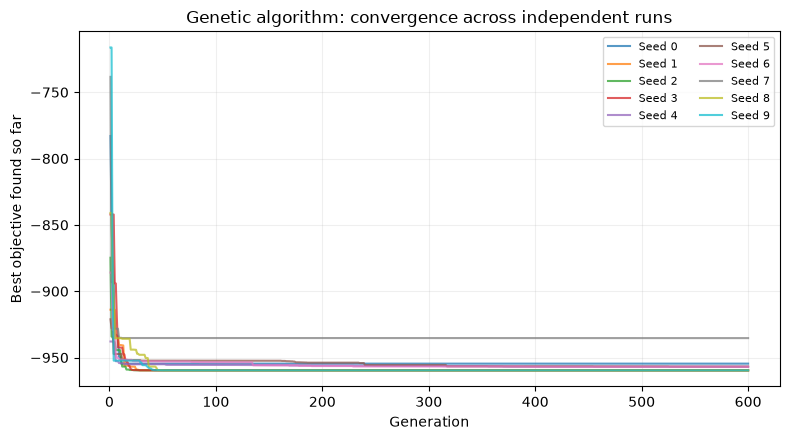

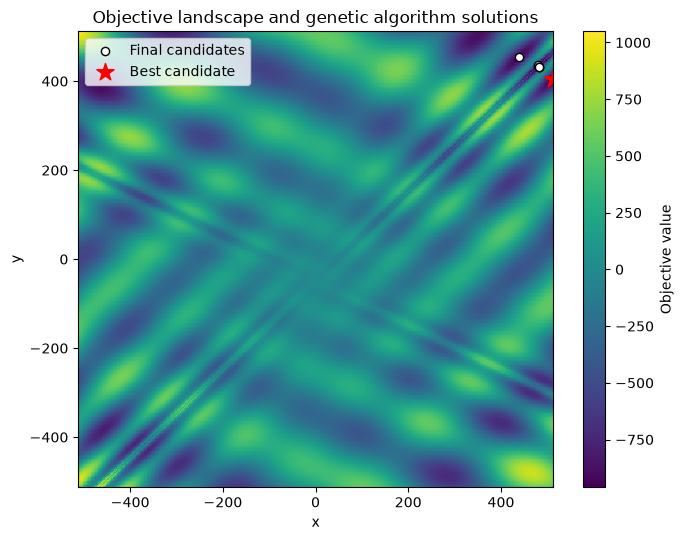

Saved all outputs to /home/taylor/Documents/Work/USC/Courses/CSCE883/Homework/Homework4/q4_results/20261115-170654-970112


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for seed, history in zip(SEEDS, histories):
    ax.plot(np.arange(1, GENERATIONS + 1), history, label=f"Seed {seed}", alpha=0.75)
ax.set(xlabel="Generation", ylabel="Best objective found so far",
       title="Genetic algorithm: convergence across independent runs")
ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(OUT / f"convergence.{ext}", dpi=180)
plt.show()

axis = np.linspace(LOWER, UPPER, 350)
xx, yy = np.meshgrid(axis, axis)
zz = objective(np.stack([xx, yy], axis=-1))
fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.pcolormesh(xx, yy, zz, shading="auto", cmap="viridis")
fig.colorbar(image, ax=ax, label="Objective value")
ax.scatter([r["x"] for r in records], [r["y"] for r in records],
           color="white", edgecolor="black", label="Final candidates", s=35)
ax.scatter(best["x"], best["y"], marker="*", color="red", s=170, label="Best candidate")
ax.set(xlabel="x", ylabel="y", xlim=(LOWER, UPPER), ylim=(LOWER, UPPER),
       title="Objective landscape and genetic algorithm solutions")
ax.legend()
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(OUT / f"landscape.{ext}", dpi=180)
plt.show()
print("Saved all outputs to", OUT)


## Interpretation
Smaller (more negative) objective values are better. Compare the best coordinates and objective with the spread of final values across seeds. Flat convergence curves indicate that a run has stopped finding improvements; they do not prove that it found the global minimum. This landscape has many local minima, so different seeds can converge to different basins. Increasing population size, mutation, generations, or independent restarts can change the result and computational cost.

The result reported here is the best observed GA candidate, without a claim of proven global optimality. The landscape grid is only a visualization; its grid points are not used to initialize or refine the genetic algorithm.

AI-use disclosure: OpenAI's Codex assistant prepared and executed this notebook and summarized its saved outputs for the written answer.